# Перенос стиля русской классической литературы

Дообучение компактной модели ruT5 для преобразования русской классической прозы в современную разговорную речь с сохранением исходного смысла.

## Цель проекта

Цель проекта - проверить, может ли небольшая sequence-to-sequence модель научиться менять стиль текста, а не просто копировать входное предложение. На вход модель получает фразу из русской классической литературы, а на выходе должна выразить ту же мысль современной лексикой и в более разговорной форме.

**Пример задачи**

> Исходный текст: У него совсем не осталось денег.  
> Предсказание: у него совсем не осталось кэша.

Главная сложность заключается в том, что при переносе стиля большая часть слов остаётся неизменной. Поэтому стандартная функция потерь гораздо сильнее поощряет копирование, чем несколько важных стилистических замен. В финальном решении этот дисбаланс уменьшается с помощью фильтрации обучающих пар и взвешенного token-level loss.

## Итоговый результат

- BLEU вырос с **69.79** у identity baseline до **71.17**.
- Современная лексика появилась в **34.81%** предсказаний вместо **0.22%**.
- Доля дословного копирования снизилась со **100%** до **54.48%**.
- chrF практически не изменился и составил **81.52**, то есть основное содержание предложений сохранилось.


In [ ]:
%pip install -q transformers sentencepiece sacrebleu gdown seaborn


In [ ]:
from difflib import SequenceMatcher
from pathlib import Path
import json
import math
import random
import re

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu
import seaborn as sns
import torch
from sklearn.model_selection import GroupShuffleSplit
from torch.nn.utils import clip_grad_norm_
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    get_linear_schedule_with_warmup,
)

SEED = 42
MODEL_NAME = "cointegrated/rut5-small"
TASK_PREFIX = "перепиши современным сленгом: "
MAX_SOURCE_LENGTH = 128
MAX_TARGET_LENGTH = 128
SMOKE_TEST = False
SMOKE_TRAIN_SIZE = 4000
SMOKE_EVAL_SIZE = 500
BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 2
EPOCHS = 3
LEARNING_RATE = 1e-4
NEW_TOKEN_WEIGHT = 3.0
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
PATIENCE = 2
CHECKPOINT_DIR = Path("checkpoints/style_transfer_final")

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

## 1. Данные и предобработка

Исходный датасет содержит 3 613 пар фрагментов: русскую классическую прозу и её современное переложение. Обучение непосредственно на длинных фрагментах оказалось неэффективным: около 88% примеров превышали контекстное окно в 512 токенов и обрезались.

Финальный pipeline предобработки:

1. нормализация пробелов и удаление технических маркеров;
2. разбиение исходных текстов и переводов на предложения;
3. сохранение только фрагментов с одинаковым количеством предложений;
4. фильтрация пар по соотношению длины и лексическому сходству;
5. удаление дубликатов и изменений только в регистре или пунктуации;
6. сохранение пар, в которых целевой текст содержит явный маркер современной речи;
7. удаление примеров длиннее 128 токенов модели.

В результате получаются короткие и информативные обучающие примеры без обрезания текста.


In [ ]:
DATA_FILE_ID = "1wn6jpF5-FeaZIo2oqSspSvbfjIiVa8F7"
DATA_PATH = Path("data/classical_to_slang.csv")
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    gdown.download(id=DATA_FILE_ID, output=str(DATA_PATH), quiet=False)

raw_df = pd.read_csv(DATA_PATH).dropna(subset=["chunk", "translate"])
raw_df = raw_df.reset_index().rename(columns={"index": "group_id"})

pd.Series({
    "rows": len(raw_df),
    "missing source": raw_df["chunk"].isna().sum(),
    "missing target": raw_df["translate"].isna().sum(),
}, name="count").to_frame()


,count
rows,3613
missing source,0
missing target,0


In [ ]:
def normalize_text(value: str) -> str:
    value = re.sub(r"\{\d+\}", " ", value)
    value = value.replace("\u00a0", " ")
    value = re.sub(r"\s+", " ", value)
    return value.strip()

def split_sentences(value: str) -> list[str]:
    value = normalize_text(value)
    return [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?…])\s+", value)
        if sentence.strip()
    ]

def word_tokens(value: str) -> list[str]:
    return re.findall(r"[а-яёa-z0-9]+", value.lower())

STYLE_MARKERS = set('''
вайб вайба вайбе вайбом тильт тильте тильта бро чел чела кринж кринжа
кринжово кэш кэша жестко жесткий жесткая жесткое лютый лютая люто npc
трэш ливнуть ливнул ливает зачекать зачекал зачекали чекать чекает чекал
чекнул чекнуть зашквар воркать воркает воркал ворк бабки база базу слэй
шмот лонгрид имбовый имбовая имбово броук паничку флексить флексил флексит
профит инсайд скуф делулу краш зумер зумеры зумерами донат донаты донатов
задонатить факап факапы факапов чиллить чиллит чилил рофл рофлить рофлит
фетиш мув мувы баг баги никнейм стрим вписка вписки офис нетворкинг фуд
кейс кейсы душно душнила задиссить
'''.split())

records = []
for row in raw_df.itertuples(index=False):
    source_sentences = split_sentences(row.chunk)
    target_sentences = split_sentences(row.translate)

    if len(source_sentences) != len(target_sentences):
        continue

    for source, target in zip(source_sentences, target_sentences):
        source_words = word_tokens(source)
        target_words = word_tokens(target)
        length_ratio = len(target_words) / max(len(source_words), 1)
        similarity = SequenceMatcher(
            None,
            source_words,
            target_words,
        ).ratio()
        new_style_markers = sorted(
            (set(target_words) - set(source_words)) & STYLE_MARKERS
        )

        if not (4 <= len(source_words) <= 80 and 4 <= len(target_words) <= 80):
            continue
        if not (0.65 <= length_ratio <= 1.5):
            continue
        if not (0.55 <= similarity < 0.97):
            continue
        if not new_style_markers:
            continue

        records.append({
            "group_id": row.group_id,
            "source": source,
            "target": target,
            "similarity": similarity,
            "style_markers": ", ".join(new_style_markers),
        })

pairs = pd.DataFrame(records).drop_duplicates("source").reset_index(drop=True)
display(pairs[["similarity"]].describe().round(3))
display(
    pairs[["source", "target", "style_markers", "similarity"]]
    .sample(5, random_state=SEED)
)


,similarity
count,8973.000
mean,0.843
std,0.091
min,0.550
25%,0.800
50%,0.857
75%,0.914
max,0.970


,source,target,style_markers,similarity
6649,"Смотреть в цепи нечего было, так как и с того ...","Чекать в цепи было нечего, так как и с того ме...","флексить, чекать",0.906250
93,"Напуганному воображению Ваксина казалось, что ...","напуганному воображению ваксина казалось, что ...",чекает,0.937500
6163,"Ст[епанида Трофимовна] Эх, голубчик, не судись...","ст[епанида трофимовна] эх, бро, не судись, луч...",бро,0.916667
6830,"Император Франц, румяный длиннолицый молодой ч...","Император Франц, румяный длиннолицый молодой ч...",чекал,0.926829
1665,С Анной Павловной танцевал мазурку черный офиц...,с анной павловной флексил мазурку черный офице...,флексил,0.928571


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
pairs["model_input"] = TASK_PREFIX + pairs["source"]

source_tokens = tokenizer(
    pairs["model_input"].tolist(),
    add_special_tokens=True,
    truncation=False,
)["input_ids"]
target_tokens = tokenizer(
    pairs["target"].tolist(),
    add_special_tokens=True,
    truncation=False,
)["input_ids"]

pairs["source_tokens"] = [len(value) for value in source_tokens]
pairs["target_tokens"] = [len(value) for value in target_tokens]
pairs = pairs[
    (pairs["source_tokens"] <= MAX_SOURCE_LENGTH)
    & (pairs["target_tokens"] <= MAX_TARGET_LENGTH)
].reset_index(drop=True)

pd.Series({
    "aligned changed pairs": len(pairs),
    "median source tokens": pairs["source_tokens"].median(),
    "median target tokens": pairs["target_tokens"].median(),
    "max source tokens": pairs["source_tokens"].max(),
    "max target tokens": pairs["target_tokens"].max(),
}, name="value").to_frame()


,value
aligned changed pairs,8845.0
median source tokens,38.0
median target tokens,32.0
max source tokens,128.0
max target tokens,128.0


### Датасет после обработки

После выравнивания предложений, фильтрации, удаления дубликатов и проверки длины осталось 8 845 пар. Медианная длина исходного предложения - 38 токенов; ни один сохранённый пример не превышает лимит в 128 токенов.


## 2. Разбиение данных без утечки

Предложения из одного литературного фрагмента могут содержать одинаковых персонажей, лексику и контекст. Случайное разбиение отдельных предложений могло бы завысить качество модели. Поэтому разбиение выполняется по `group_id`: каждый исходный фрагмент целиком попадает только в train, validation или test.


In [ ]:
first_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_index, temp_index = next(
    first_split.split(pairs, groups=pairs["group_id"])
)
train_df = pairs.iloc[train_index].reset_index(drop=True)
temp_df = pairs.iloc[temp_index].reset_index(drop=True)

second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_index, test_index = next(
    second_split.split(temp_df, groups=temp_df["group_id"])
)
val_df = temp_df.iloc[val_index].reset_index(drop=True)
test_df = temp_df.iloc[test_index].reset_index(drop=True)

if SMOKE_TEST:
    train_df = train_df.sample(
        min(SMOKE_TRAIN_SIZE, len(train_df)),
        random_state=SEED,
    ).reset_index(drop=True)
    val_df = val_df.sample(
        min(SMOKE_EVAL_SIZE, len(val_df)),
        random_state=SEED,
    ).reset_index(drop=True)
    test_df = test_df.sample(
        min(SMOKE_EVAL_SIZE, len(test_df)),
        random_state=SEED,
    ).reset_index(drop=True)

display(pd.Series({
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df),
}, name="rows").to_frame())

assert set(train_df["group_id"]).isdisjoint(val_df["group_id"])
assert set(train_df["group_id"]).isdisjoint(test_df["group_id"])
assert set(val_df["group_id"]).isdisjoint(test_df["group_id"])


,rows
train,7025
validation,915
test,905


### Итоговое разбиение

| Выборка | Количество пар |
|---|---:|
| Train | 7 025 |
| Validation | 915 |
| Test | 905 |

Проверки в ячейке выше подтверждают, что группы исходных фрагментов не пересекаются.


## 3. Оценка качества и identity baseline

Identity baseline возвращает входное предложение без изменений. Для этой задачи это сильная отправная точка, потому что большая часть слов в целевом тексте совпадает с исходным.

Используются четыре взаимодополняющие метрики:

- **BLEU** и **chrF** оценивают сходство с эталонным переложением;
- **style marker rate** показывает, в какой доле предсказаний встречается современная лексика;
- **marker recall** показывает, сколько стилевых маркеров из эталона воспроизвела модель;
- **exact copy rate** показывает, как часто нормализованное предсказание полностью совпадает с исходным текстом.

Хорошая модель должна чаще менять стиль и реже копировать текст, не допуская существенного падения BLEU и chrF.


In [ ]:
def compute_metrics(references: list[str], predictions: list[str]) -> dict[str, float]:
    marker_recalls = []
    for reference, prediction in zip(references, predictions):
        reference_markers = set(word_tokens(reference)) & STYLE_MARKERS
        prediction_markers = set(word_tokens(prediction)) & STYLE_MARKERS
        marker_recalls.append(
            len(reference_markers & prediction_markers)
            / max(len(reference_markers), 1)
        )
    return {
        "BLEU": sacrebleu.corpus_bleu(predictions, [references]).score,
        "chrF": sacrebleu.corpus_chrf(
            predictions,
            [references],
            char_order=6,
            beta=2,
        ).score,
        "style marker rate": 100 * np.mean([
            bool(set(word_tokens(value)) & STYLE_MARKERS)
            for value in predictions
        ]),
        "marker recall": 100 * np.mean(marker_recalls),
    }

def exact_copy_rate(sources: list[str], predictions: list[str]) -> float:
    return 100 * np.mean([
        word_tokens(source) == word_tokens(prediction)
        for source, prediction in zip(sources, predictions)
    ])

identity_val_metrics = compute_metrics(
    val_df["target"].tolist(),
    val_df["source"].tolist(),
)
identity_test_metrics = compute_metrics(
    test_df["target"].tolist(),
    test_df["source"].tolist(),
)
identity_val_metrics["exact copy rate"] = 100.0
identity_test_metrics["exact copy rate"] = 100.0

pd.DataFrame(
    [identity_val_metrics, identity_test_metrics],
    index=["identity / validation", "identity / test"],
).round(2)


,BLEU,chrF,style marker rate,marker recall,exact copy rate
identity / validation,69.84,81.60,0.11,0.05,100.0
identity / test,69.79,81.71,0.22,0.11,100.0


## 4. Модель

В качестве базовой модели используется `cointegrated/rut5-small` - компактный русскоязычный text-to-text Transformer. К каждому исходному предложению добавляется инструкция `перепиши современным сленгом:`. Максимальная длина исходного и целевого текста составляет 128 токенов.

Компактная модель выбрана для того, чтобы эксперимент можно было воспроизвести в обычной GPU-сессии Google Colab.


In [ ]:
class StyleTransferDataset(Dataset):
    def __init__(self, frame: pd.DataFrame):
        self.frame = frame.reset_index(drop=True)

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict:
        row = self.frame.iloc[index]
        inputs = tokenizer(
            row["model_input"],
            max_length=MAX_SOURCE_LENGTH,
            truncation=True,
        )
        inputs["labels"] = tokenizer(
            text_target=row["target"],
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
        )["input_ids"]
        return inputs

model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model)

def make_loader(frame: pd.DataFrame, shuffle: bool) -> DataLoader:
    return DataLoader(
        StyleTransferDataset(frame),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        collate_fn=collator,
    )

train_loader = make_loader(train_df, True)
val_loader = make_loader(val_df, False)
test_loader = make_loader(test_df, False)


In [ ]:
def decode_labels(labels: torch.Tensor) -> list[str]:
    labels = labels.detach().clone()
    labels[labels == -100] = tokenizer.pad_token_id
    return tokenizer.batch_decode(labels, skip_special_tokens=True)

@torch.no_grad()
def evaluate(loader: DataLoader) -> tuple[float, dict[str, float], list[str], list[str]]:
    model.eval()
    losses, predictions, references = [], [], []

    for batch in tqdm(loader, leave=False):
        batch = {key: value.to(device) for key, value in batch.items()}
        outputs = model(**batch)
        losses.append(outputs.loss.item())

        generated = model.generate(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"],
            max_length=MAX_TARGET_LENGTH,
            num_beams=2,
            length_penalty=0.9,
            no_repeat_ngram_size=3,
        )
        predictions.extend(
            tokenizer.batch_decode(generated, skip_special_tokens=True)
        )
        references.extend(decode_labels(batch["labels"]))

    metrics = compute_metrics(references, predictions)
    return float(np.mean(losses)), metrics, predictions, references


## 5. Взвешенная функция потерь

При использовании обычной cross-entropy неизменённые слова доминируют в loss, поэтому самой выгодной стратегией для модели становится копирование. В финальном эксперименте используется взвешенная token-level cross-entropy:

`L = sum(w_i * CE_i) / sum(w_i)`

Здесь `w_i = 3`, если целевого токена нет в исходном предложении, и `w_i = 1` во всех остальных случаях. Модель по-прежнему учится сохранять содержание, но стилистические замены получают более сильный обучающий сигнал.

### Развитие эксперимента

| Эксперимент | Наблюдение | Решение |
|---|---|---|
| Обучение на длинных фрагментах | Около 88% примеров обрезалось | Перейти к парам предложений |
| Нефильтрованные пары предложений | Модель в основном копировала вход | Удалить неизменённые и слабо изменённые пары |
| Фильтрация по стилевым маркерам | Сигнал усилился, но копирование преобладало | Добавить взвешенный loss |
| Вес новых токенов `5.0` | Сленга стало больше, но появились неестественные замены | Снизить итоговый вес до `3.0` |
| Полный отфильтрованный датасет | Лучший баланс между стилем и сохранением смысла | Использовать как финальную модель |

Модель обучается три эпохи с AdamW, gradient accumulation, gradient clipping и линейным scheduler. Лучший checkpoint выбирается по validation score, объединяющему marker recall и chrF.


01 | train 2.108 | val 0.707 | BLEU 69.99 | chrF 80.94 | markers 6.9% | copies 67.4%


02 | train 1.439 | val 0.640 | BLEU 71.02 | chrF 81.60 | markers 14.5% | copies 53.2%


03 | train 1.314 | val 0.622 | BLEU 71.13 | chrF 81.60 | markers 17.1% | copies 49.2%


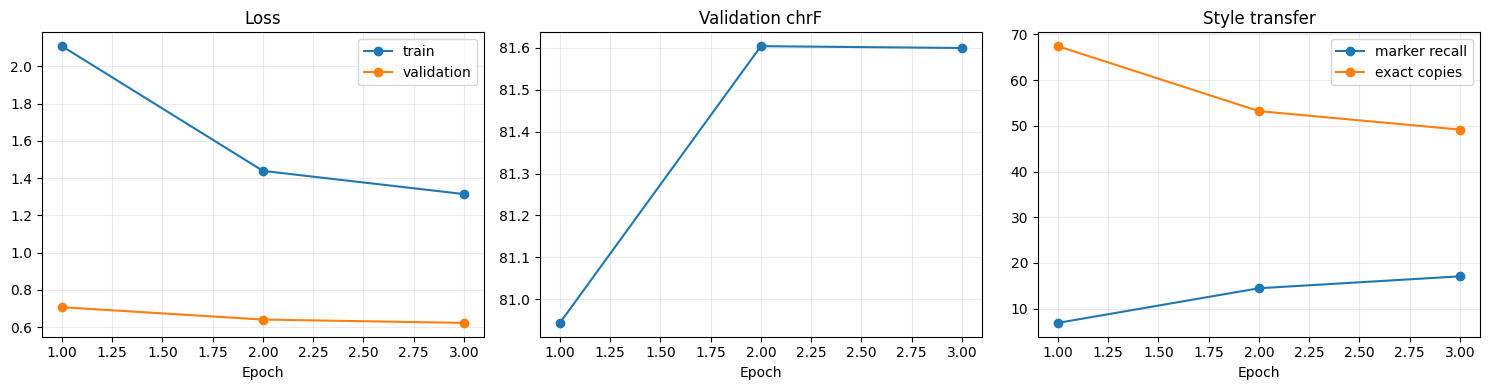

In [ ]:
def weighted_loss(batch: dict[str, torch.Tensor]) -> torch.Tensor:
    outputs = model(**batch)
    labels = batch["labels"]
    token_losses = torch.nn.functional.cross_entropy(
        outputs.logits.reshape(-1, outputs.logits.shape[-1]),
        labels.reshape(-1),
        ignore_index=-100,
        reduction="none",
    ).reshape_as(labels)
    valid_tokens = labels.ne(-100)
    appears_in_source = (
        labels.unsqueeze(-1) == batch["input_ids"].unsqueeze(1)
    ).any(dim=-1)
    weights = torch.where(
        appears_in_source,
        torch.ones_like(token_losses),
        torch.full_like(token_losses, NEW_TOKEN_WEIGHT),
    )
    weighted_tokens = weights * valid_tokens
    return (token_losses * weighted_tokens).sum() / weighted_tokens.sum()

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
updates_per_epoch = math.ceil(len(train_loader) / GRADIENT_ACCUMULATION_STEPS)
total_steps = EPOCHS * updates_per_epoch
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(WARMUP_RATIO * total_steps),
    num_training_steps=total_steps,
)

history = []
best_score = -np.inf
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_losses = []
    optimizer.zero_grad(set_to_none=True)

    for step, batch in enumerate(
        tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS}"),
        start=1,
    ):
        batch = {key: value.to(device) for key, value in batch.items()}
        loss = weighted_loss(batch)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss is not finite at epoch {epoch}, step {step}: {loss.item()}"
            )

        (loss / GRADIENT_ACCUMULATION_STEPS).backward()
        train_losses.append(loss.item())

        should_update = (
            step % GRADIENT_ACCUMULATION_STEPS == 0
            or step == len(train_loader)
        )
        if should_update:
            clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

    val_loss, val_metrics, val_predictions, _ = evaluate(val_loader)
    val_copy_rate = exact_copy_rate(
        val_df["source"].tolist(),
        val_predictions,
    )
    selection_score = val_metrics["marker recall"] + 0.25 * val_metrics["chrF"]
    result = {
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": val_loss,
        "val_BLEU": val_metrics["BLEU"],
        "val_chrF": val_metrics["chrF"],
        "val_marker_recall": val_metrics["marker recall"],
        "val_copy_rate": val_copy_rate,
        "selection_score": selection_score,
    }
    history.append(result)
    print(
        f"{epoch:02d} | train {result['train_loss']:.3f} | "
        f"val {val_loss:.3f} | BLEU {val_metrics['BLEU']:.2f} | "
        f"chrF {val_metrics['chrF']:.2f} | "
        f"markers {val_metrics['marker recall']:.1f}% | "
        f"copies {val_copy_rate:.1f}%"
    )

    if selection_score > best_score:
        best_score = selection_score
        epochs_without_improvement = 0
        CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(CHECKPOINT_DIR)
        tokenizer.save_pretrained(CHECKPOINT_DIR)
        with open(CHECKPOINT_DIR / "training_history.json", "w", encoding="utf-8") as file:
            json.dump(history, file, ensure_ascii=False, indent=2)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print("Early stopping: validation quality is no longer improving.")
            break

history_frame = pd.DataFrame(history)
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(history_frame["epoch"], history_frame["train_loss"], marker="o", label="train")
axes[0].plot(history_frame["epoch"], history_frame["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history_frame["epoch"], history_frame["val_chrF"], marker="o")
axes[1].set_title("Validation chrF")
axes[2].plot(history_frame["epoch"], history_frame["val_marker_recall"], marker="o", label="marker recall")
axes[2].plot(history_frame["epoch"], history_frame["val_copy_rate"], marker="o", label="exact copies")
axes[2].set_title("Style transfer")
axes[2].legend()
for axis in axes:
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Динамика обучения

Train loss и validation loss уменьшаются на всех трёх эпохах. Одновременно marker recall на validation растёт с 6.9% до 17.1%, а exact copy rate снижается с 67.4% до 49.2%. Таким образом, модель постепенно осваивает больше стилистических замен без разрушения метрик, отвечающих за сохранение содержания.


## 6. Финальная оценка

Лучший checkpoint оценивается один раз на 905 ранее не встречавшихся парах предложений. Identity baseline и дообученная модель сравниваются на одной и той же тестовой выборке.


In [ ]:
model = AutoModelForSeq2SeqLM.from_pretrained(CHECKPOINT_DIR).to(device)
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT_DIR)

test_loss, model_metrics, predictions, references = evaluate(test_loader)
model_metrics["exact copy rate"] = exact_copy_rate(
    test_df["source"].tolist(),
    predictions,
)
comparison = pd.DataFrame(
    [identity_test_metrics, model_metrics],
    index=["identity baseline", "fine-tuned ruT5"],
).round(2)
comparison.insert(0, "loss", [np.nan, test_loss])
display(comparison)


,loss,BLEU,chrF,style marker rate,marker recall,exact copy rate
identity baseline,NaN,69.79,81.71,0.22,0.11,100.00
fine-tuned ruT5,0.592628,71.17,81.52,34.81,13.74,54.48


### Результаты на тестовой выборке

| Модель | BLEU | chrF | Style marker rate | Marker recall | Exact copy rate |
|---|---:|---:|---:|---:|---:|
| Identity baseline | 69.79 | **81.71** | 0.22% | 0.11% | 100.00% |
| Fine-tuned ruT5 | **71.17** | 81.52 | **34.81%** | **13.74%** | **54.48%** |

Дообученная модель превосходит baseline по BLEU и значительно улучшает обе стилевые метрики. Снижение chrF всего на 0.19 пункта невелико по сравнению с ростом числа стилистических изменений. Это указывает на хороший баланс между преобразованием стиля и сохранением исходного содержания.


In [ ]:
examples = test_df[["source", "target"]].copy()
examples["prediction"] = predictions
examples["source_similarity"] = [
    SequenceMatcher(None, source.lower(), prediction.lower()).ratio()
    for source, prediction in zip(examples["source"], examples["prediction"])
]
display(examples.sample(20, random_state=SEED))


,source,target,prediction,source_similarity
70,"- ни с того ни с сего нахмурился, наершился и ...","— ни с того ни с сего нахмурился, наершился и ...","— ни с того ни со сего нахмурился, наершился и...",0.977444
457,"Воображение мое спешило нарисовать палатки, ст...","воображение мое спешило нарисовать палатки, ст...","воображение мое спешило нарисовать палатки, ст...",1.000000
218,"Только теперь, сидя за пианино, она впервые яс...","только теперь, сидя за пианино, она впервые яс...","Только теперь, сидя за пианино, она впервые яс...",0.986014
250,"Когда она была больна, то он схватил себя за г...","когда она была в тильте, то он схватил себя за...","когда она была больна, то он схватил себя за г...",1.000000
39,"""Почитаю-ка ему свое произведение, - надумал З...","""почитаю-ка ему свой лонгрид, — надумал зельте...","""почитаю-ка ему свой кейс, — надумал Зельтерский.",0.811321
868,"Он обратился было к сторонам, к прокурору и за...","Он обратился было к сторонам, к прокурору и за...","он обратился было к сторонам, к прокурору и за...",1.000000
486,Доктор нервно засуетился и стал искать своей ш...,доктор нервно засуетился и стал искать свой шм...,доктор нервно засуетился и стал искать своей ш...,1.000000
110,"Посудина, брат, не подкупишь, не-ет!","посудина, бро, не подкупишь, не-ет!","посудина, бро, не подкупишь, не-ет!",0.957746
72,"На лице провизора изобразилось ""тьфу!"".","на лице провизора изобразилось ""кринж!"".","на лице провизора изобразилось ""тильт!"".",0.936709
86,"Это еще молодой человек, красивый, с благородн...","это еще молодой чел, красивый, с благородной о...","это еще молодой чел, красивый, с благородной о...",0.972603


## 7. Качественный анализ и ошибки

Случайные примеры из тестовой выборки показывают удачные замены: `произведение → кейс`, `брат → бро`, `молодой человек → молодой чел`, `деньги → бабки`. Одновременно видны оставшиеся проблемы: некоторые предложения копируются, а замены вроде `тьфу → тильт` соответствуют выбранному стилю, но не полностью сохраняют точный смысл.

Качественный анализ необходим, потому что автоматические метрики могут занизить оценку допустимого альтернативного переложения или, наоборот, не заметить неестественную фразу с большим количеством совпадающих слов.


## 8. Проверка на собственных примерах

Следующие предложения составлены вручную и не входят в train, validation или test. Они позволяют качественно проверить работу модели на новых входных данных.


In [ ]:
@torch.no_grad()
def translate(text: str) -> str:
    model.eval()
    prompt = TASK_PREFIX + normalize_text(text)
    inputs = tokenizer(
        prompt,
        max_length=MAX_SOURCE_LENGTH,
        truncation=True,
        return_tensors="pt",
    ).to(device)
    input_length = inputs["input_ids"].shape[1]
    output_limit = min(MAX_TARGET_LENGTH, max(16, int(input_length * 1.5)))
    generated = model.generate(
        **inputs,
        max_length=output_limit,
        num_beams=2,
        length_penalty=0.9,
        no_repeat_ngram_size=3,
    )
    return tokenizer.decode(generated[0], skip_special_tokens=True)

custom_examples = [
    "Я вас любил: любовь еще, быть может, в душе моей угасла не совсем.",
    "Этот молодой человек произвел на меня неприятное впечатление.",
    "Мне совершенно не хочется сегодня работать.",
    "Он очень расстроился из-за этой неудачи.",
    "У него совсем не осталось денег.",
]
pd.DataFrame({
    "source": custom_examples,
    "prediction": [translate(value) for value in custom_examples],
})


,source,prediction
0,"Я вас любил: любовь еще, быть может, в душе мо...","я вас любил: любовь еще, быть может, в душе мо..."
1,Этот молодой человек произвел на меня неприятн...,этот молодой чел произвел на меня кринжовый вайб.
2,Мне совершенно не хочется сегодня работать.,мне совершенно не хочется сегодня воркать.
3,Он очень расстроился из-за этой неудачи.,он очень расстроился из-за этого кринжа.
4,У него совсем не осталось денег.,у него совсем не осталось кэша.


### Интерпретация примеров

Модель переносит несколько типичных преобразований на новые предложения:

- `молодой человек → молодой чел`;
- `неприятное впечатление → кринжовый вайб`;
- `работать → воркать`;
- `неудача → кринж`;
- `деньги → кэш`.

Цитата Пушкина остаётся почти неизменной. Это показывает одно из ограничений модели: для абстрактного или поэтического текста она не всегда находит уместную стилистическую замену.


## 9. Вывод

Финальная модель научилась заметно изменять стиль, сохраняя основное содержание предложений. Она превзошла копирующий baseline по BLEU, сохранила практически такой же chrF, увеличила style marker rate более чем на 34 процентных пункта и снизила долю дословного копирования примерно на 45 процентных пунктов.

Эксперимент также показывает, что качество данных и формулировка функции потерь важнее простого увеличения времени обучения. Разбиение на предложения устранило сильное обрезание текста, фильтрация усилила полезный обучающий сигнал, а взвешенный loss напрямую решил проблему копирования.
